# Visual Guide: SO(k)-Invariant Gauge Rigidity & The Triangle Anomaly
### An Intuitive Exploration for Engineers, Physicists, and Curious Minds
**Paper Reference:** `GS-002` (`so_k_invariant_gauge_classification`)  

---

## 1. The Core Mystery: Rotating an Error Vector
Imagine two sensors measuring an error in 2D space: an $x$-offset and a $y$-offset.

- **Observer A (Taxicab / Manhattan):** Measures independent channels: $|x| + |y|$. If the sensor drifts by $1$ unit along the $x$-axis, the error is $1$. If that same $1$-unit drift rotates to a $45^\circ$ angle, the error becomes $\frac{1}{\sqrt{2}} + \frac{1}{\sqrt{2}} = \sqrt{2} \approx 1.414$!
- **Observer B (Euclidean / Rotational):** Measures physical distance: $\sqrt{x^2 + y^2} = 1.0$, regardless of which way the vector points.

This notebook demonstrates why **rotational symmetry $\mathrm{SO}(k)$** strictly forces Observer B's choice, and how this produces measurable differences on network loops.

Plots illustrate declared gauges on finite data. Their assertions are numerical checks, not universal invariance proofs. See the [study guide](../docs/study_guide.md), [Landau quiz](../docs/landau_quiz.md), and [publication review](../docs/publication_review.md).


In [1]:
import sys
import math
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

def _boot_libs(*names):
    """Robustly resolve and import library directories regardless of CWD."""
    cwd = Path.cwd().resolve()
    search_dirs = [cwd] + list(cwd.parents)
    for ancestor in [cwd] + list(cwd.parents):
        cand = ancestor / "coda_atlas" / "papers" / "projection_obstruction" / "so_k_invariant_gauge_classification"
        if cand.exists():
            search_dirs.insert(0, cand)
            break
    for name in names:
        for base in search_dirs:
            p = (base / name).resolve()
            if p.is_dir() and p.exists():
                if str(p) not in sys.path:
                    sys.path.insert(0, str(p))
                return str(p)
            sub = base / "so_k_invariant_gauge_classification" / name
            if sub.is_dir() and sub.exists():
                sub_res = sub.resolve()
                if str(sub_res) not in sys.path:
                    sys.path.insert(0, str(sub_res))
                return str(sub_res)
    raise FileNotFoundError(f"none of {names} found from {cwd}")

code_dir = _boot_libs("code")

from so_k_gauge import (
    EuclideanGauge,
    CoordinateL1Gauge,
    GraphComplex,
    Cochain,
    MixedNormSolver,
    CoordinateL1Solver,
    analyze_triangle_separation,
    analyze_dimension_scaling
)
print('Successfully loaded so_k_gauge!')

Successfully loaded so_k_gauge!


## 2. Interactive Visualization: The Norm of a Rotated Vector
Let us rotate a unit vector $\vec{v}(\theta) = (\cos\theta, \sin\theta)$ in the plane from $0$ to $2\pi$ and observe how different observers evaluate its magnitude.

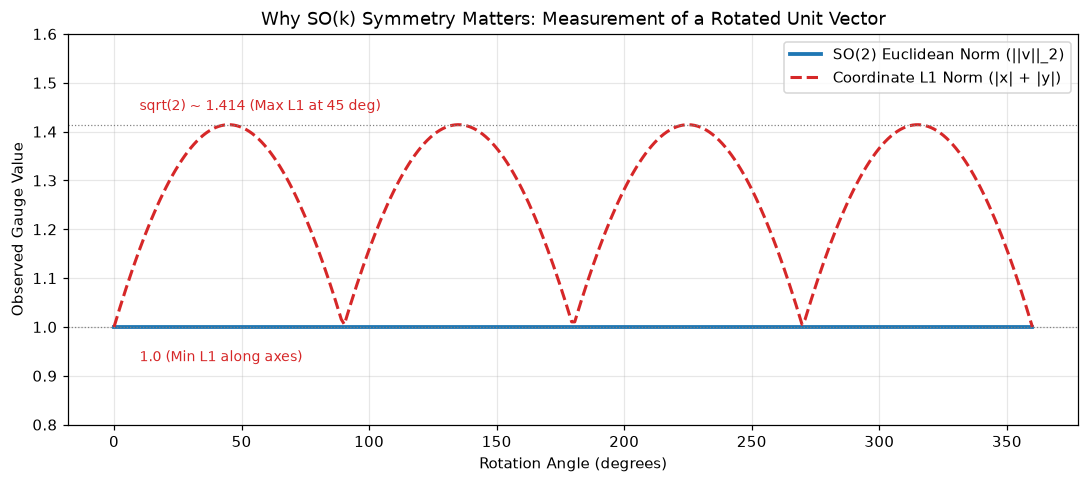

In [2]:
angles = np.linspace(0, 2 * np.pi, 300)
l2_gauge = EuclideanGauge(1.0)
l1_gauge = CoordinateL1Gauge(1.0)

euc_vals = []
l1_vals = []

for theta in angles:
    v = np.array([np.cos(theta), np.sin(theta)])
    euc_vals.append(l2_gauge(v))
    l1_vals.append(l1_gauge(v))

plt.figure(figsize=(10, 4.5))
plt.plot(np.degrees(angles), euc_vals, label='SO(2) Euclidean Norm (||v||_2)', color='#1f77b4', lw=2.5)
plt.plot(np.degrees(angles), l1_vals, label='Coordinate L1 Norm (|x| + |y|)', color='#d62728', lw=2, ls='--')
plt.axhline(1.0, color='gray', lw=0.8, ls=':')
plt.axhline(np.sqrt(2.0), color='gray', lw=0.8, ls=':')
plt.text(10, np.sqrt(2.0) + 0.03, 'sqrt(2) ~ 1.414 (Max L1 at 45 deg)', color='#d62728', fontsize=9)
plt.text(10, 1.0 - 0.07, '1.0 (Min L1 along axes)', color='#d62728', fontsize=9)

plt.title('Why SO(k) Symmetry Matters: Measurement of a Rotated Unit Vector')
plt.xlabel('Rotation Angle (degrees)')
plt.ylabel('Observed Gauge Value')
plt.ylim(0.8, 1.6)
plt.grid(True, alpha=0.3)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

assert np.allclose(euc_vals, 1, atol=1e-12)
assert min(l1_vals) >= 1 - 1e-12 and max(l1_vals) <= math.sqrt(2) + 1e-12
assert max(l1_vals) > 1.4

### Key Insight:
The Euclidean norm remains perfectly constant at $1.0$ at all angles. The coordinate $\ell^1$ norm oscillates between $1.0$ (when pointing along a coordinate axis) and $\sqrt{2} \approx 1.414$ (when pointing along the diagonal).

If an observer declares that **the direction of an error in the plane should not affect its measured magnitude**, that observer is **mathematically forced** to use the Euclidean norm (Theorem 3.1).

## 3. The Finite Triangle Anomaly: 2.0 vs 1.414
Consider a minimal closed network of 3 vertices $0 \to 1 \to 2 \to 0$ with 2D vector defects on the edges:
- Edge $0 \to 1$: $\omega_{01} = (1, 0)$
- Edge $1 \to 2$: $\omega_{12} = (0, 1)$
- Edge $2 \to 0$: $\omega_{20} = (0, 0)$

The total cycle circulation is $c = (1, 0) + (0, 1) + (0, 0) = (1, 1)$.

In [3]:
sep = analyze_triangle_separation()
print('--- Finite Triangle Separation (GS-002 Theorem 5.2) ---')
print(f'Total Cycle Circulation S(omega): {sep["circulation"]}')
print(f'Coordinate-Separable L1 Obstruction (Phi_1,1): {sep["phi_11_coordinate_l1"]:.4f}')
print(f'SO(2)-Invariant Mixed Obstruction (Phi_2,1):    {sep["phi_21_euclidean_so2"]:.4f}')
print(f'Ratio Phi_1,1 / Phi_2,1:                      {sep["ratio"]:.4f} (Exact sqrt(2))')
print(f'Squared Ratio (Phi_1,1)^2 / (Phi_2,1)^2:      {sep["squared_ratio"]:.4f} (Exact 2.0)')

assert math.isclose(sep['phi_11_coordinate_l1'], 2)
assert math.isclose(sep['phi_21_euclidean_so2'], math.sqrt(2))
assert math.isclose(sep['squared_ratio'], 2)

--- Finite Triangle Separation (GS-002 Theorem 5.2) ---
Total Cycle Circulation S(omega): [1.0, 1.0]
Coordinate-Separable L1 Obstruction (Phi_1,1): 2.0000
SO(2)-Invariant Mixed Obstruction (Phi_2,1):    1.4142
Ratio Phi_1,1 / Phi_2,1:                      1.4142 (Exact sqrt(2))
Squared Ratio (Phi_1,1)^2 / (Phi_2,1)^2:      2.0000 (Exact 2.0)


Let us visualize the triangle network and the vector defects on each edge.

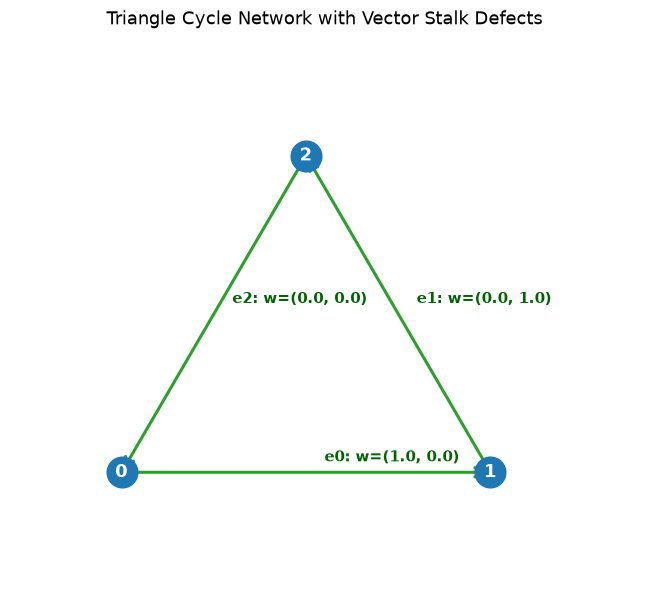

In [4]:
# Vertex coordinates in equilateral triangle
v_coords = np.array([
    [0.0, 0.0],           # Node 0
    [1.0, 0.0],           # Node 1
    [0.5, np.sqrt(3)/2]   # Node 2
])

fig, ax = plt.subplots(figsize=(6, 5.5))
# Draw edges
edges = [(0, 1), (1, 2), (2, 0)]
defects = [(1.0, 0.0), (0.0, 1.0), (0.0, 0.0)]

for idx, (u, v) in enumerate(edges):
    p_u, p_v = v_coords[u], v_coords[v]
    ax.annotate('', xy=p_v, xytext=p_u,
                arrowprops=dict(arrowstyle='->', color='#2ca02c', lw=2, mutation_scale=15))
    mid = (p_u + p_v) / 2.0
    ax.text(mid[0] + 0.05, mid[1] + 0.03, f'e{idx}: w={defects[idx]}', color='darkgreen', fontsize=10, weight='bold')

# Draw nodes
for i, p in enumerate(v_coords):
    ax.scatter(p[0], p[1], s=400, color='#1f77b4', zorder=5)
    ax.text(p[0], p[1], str(i), color='white', ha='center', va='center', fontsize=12, weight='bold', zorder=6)

ax.set_title('Triangle Cycle Network with Vector Stalk Defects')
ax.set_xlim(-0.3, 1.4)
ax.set_ylim(-0.3, 1.2)
ax.axis('off')
plt.tight_layout()
plt.show()

## 4. Higher-Dimensional Scaling: The $\sqrt{k}$ Growth
What happens when defects live in higher dimensions ($k = 2, 3, 4, \dots, 25$)?
For an equal diagonal defect $(1, 1, \dots, 1) \in \mathbb{R}^k$:
- Coordinate Observer: $\Phi_{1,1} = k$
- $\mathrm{SO}(k)$ Observer: $\Phi_{2,1} = \sqrt{k}$
- Discrepancy Ratio: $\frac{\Phi_{1,1}}{\Phi_{2,1}} = \sqrt{k}$

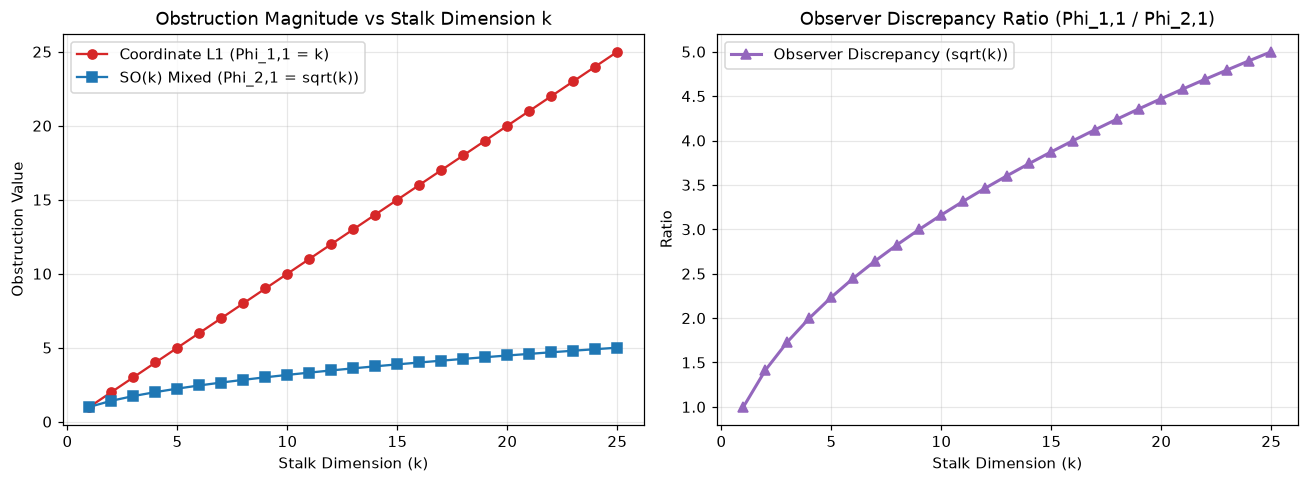

In [5]:
dims = list(range(1, 26))
scaling = analyze_dimension_scaling(dims)

k_vals = [s['dimension_k'] for s in scaling]
phi11_vals = [s['phi_11'] for s in scaling]
phi21_vals = [s['phi_21'] for s in scaling]
ratios = [s['discrepancy_ratio'] for s in scaling]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

ax1.plot(k_vals, phi11_vals, label='Coordinate L1 (Phi_1,1 = k)', color='#d62728', marker='o')
ax1.plot(k_vals, phi21_vals, label='SO(k) Mixed (Phi_2,1 = sqrt(k))', color='#1f77b4', marker='s')
ax1.set_title('Obstruction Magnitude vs Stalk Dimension k')
ax1.set_xlabel('Stalk Dimension (k)')
ax1.set_ylabel('Obstruction Value')
ax1.grid(True, alpha=0.3)
ax1.legend()

ax2.plot(k_vals, ratios, label='Observer Discrepancy (sqrt(k))', color='#9467bd', marker='^', lw=2)
ax2.set_title('Observer Discrepancy Ratio (Phi_1,1 / Phi_2,1)')
ax2.set_xlabel('Stalk Dimension (k)')
ax2.set_ylabel('Ratio')
ax2.grid(True, alpha=0.3)
ax2.legend()

plt.tight_layout()
plt.show()

assert np.allclose(phi11_vals, dims)
assert np.allclose(phi21_vals, np.sqrt(dims))
assert np.allclose(ratios, np.sqrt(dims))

## 5. Conclusion: What This Teaches Us
1. **No Universal Distance:** How big an error is depends strictly on the declared observer geometry.
2. **Rotational Symmetry Forces Euclidean Norm:** If physical rotation does not change the error magnitude, you must use $\ell^2$ on vector stalks.
3. **Independent Channels Force Coordinate $\ell^1$:** If $x$ and $y$ are independent sensors (e.g. temperature and voltage), you must use $\ell^1$.
4. **The Gap Grows with Dimension:** In high-dimensional vector spaces, the two observers disagree by a factor of $\sqrt{k}$, which can be enormous!

## 6. Local rotation symmetry leaves the outer aggregate open

For two unit edge defects, the strongly additive sum is 2 and the global
Euclidean aggregate is sqrt(2). Both are invariant under independent local
rotations. The edgewise sum requires a separate aggregation declaration.


In [6]:
edge_unit_data = np.array([[1.0, 0.0], [0.0, 1.0]])
strong_sum = sum(l2_gauge(x) for x in edge_unit_data)
global_l2 = np.linalg.norm(edge_unit_data)
assert math.isclose(strong_sum, 2)
assert math.isclose(global_l2, math.sqrt(2))
assert not math.isclose(strong_sum, global_l2)
print(f'Strong edge sum: {strong_sum}; independent-rotation global L2: {global_l2}')


Strong edge sum: 2.0; independent-rotation global L2: 1.4142135623730951
